In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 84.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 11.3 MB/s eta 0:00:00


In [2]:
import os
import glob

zip_files = glob.glob("/content/*.zip")

print(zip_files)

['/content/Labeled_full_pill.v2i.yolov8.zip']


In [3]:
import zipfile
import os

zip_file = zip_files[0]

extract_path = "/content/Pill_anomaly_Detection_dataset"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [4]:
from ultralytics import YOLO
import ultralytics
import os
import glob
import zipfile
import shutil

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [5]:
model = YOLO("yolov8n.pt")

In [6]:
data_yaml = "/content/Pill_anomaly_Detection_dataset/data.yaml"

results = model.train(
    data=data_yaml,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/runs",
    name="Pill_anomaly_Detection",
    save=True,
    save_period=10,
    val=True,
    seed=42,
    patience=15,
    workers=2
)

Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Pill_anomaly_Detection_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=Pill_anomaly_Detection, nbs=64, nms=Non

In [7]:
best_model = YOLO(
    "/content/runs/Pill_anomaly_Detection/weights/best.pt"
)

In [8]:
metrics = best_model.val(
    data=data_yaml,
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,428 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1049.0±304.0 MB/s, size: 30.2 KB)
val: Scanning /content/Pill_anomaly_Detection_dataset/valid/labels.cache... 678 images, 79 backgrounds, 30 corrupt: 100% ━━━━━━━━━━━━ 678/678 218.7Mit/s 0.0s
val: /content/Pill_anomaly_Detection_dataset/valid/images/IMG20230207192156_jpg.rf.e2ecf2436d3b03331d8d1c00de8efda7.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/Pill_anomaly_Detection_dataset/valid/images/IMG20230207192241_jpg.rf.685a28783ad97108552c5a669ab60f9a.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/Pill_anomaly_Detection_dataset/valid/images/IMG20230207192242_jpg.rf.220cfb5c340b5371f47ef631cd16dad6.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /content/Pill_anomaly_

In [9]:
print("mAP50     :", metrics.box.map50)
print("mAP50-95  :", metrics.box.map)
print("Precision :", metrics.box.mp)
print("Recall    :", metrics.box.mr)

mAP50     : 0.8348469236668665
mAP50-95  : 0.5898619156985784
Precision : 0.9509018365155143
Recall    : 0.663523540514043


In [10]:
test_images = "/content/Pill_anomaly_Detection_dataset/test/images"

test_results = best_model.predict(
    source=test_images,
    conf=0.25,
    imgsz=640,
    save=True,
    project="/content/runs",
    name="test_predictions"
)


image 1/339 /content/Pill_anomaly_Detection_dataset/test/images/1000_F_420127490_zYfufzLT1jVxPzLVJzIh46ZI6FSeML3B_jpg.rf.bda13113278c48765835f95ce335b65d.jpg: 640x640 16 tablets, 7.2ms
image 2/339 /content/Pill_anomaly_Detection_dataset/test/images/1003948616_jpg.rf.f89e215f33dc0835b4f49d5705aad665.jpg: 640x640 23 capsules, 9.7ms
image 3/339 /content/Pill_anomaly_Detection_dataset/test/images/101184224_jpg.rf.071ff8296b579f4429df2ba14e14d8d5.jpg: 640x640 13 tablets, 7.4ms
image 4/339 /content/Pill_anomaly_Detection_dataset/test/images/1040g008314og5s1v1e405ogcinp40idpu1u08c8-nd_dft_wlteh_webp_3_webp_jpg.rf.065e84e84b27a1342701156f25b837fc.jpg: 640x640 (no detections), 7.9ms
image 5/339 /content/Pill_anomaly_Detection_dataset/test/images/1040g008314og5s1v1e6g5ogcinp40idpgnp8g58-nd_dft_wlteh_webp_3_webp_jpg.rf.28fb2286b33444d4aae98492bf0b5975.jpg: 640x640 (no detections), 7.2ms
image 6/339 /content/Pill_anomaly_Detection_dataset/test/images/1040g00831bi7llbp0k00497f5q90hlj6sa2t8a8-nd_df

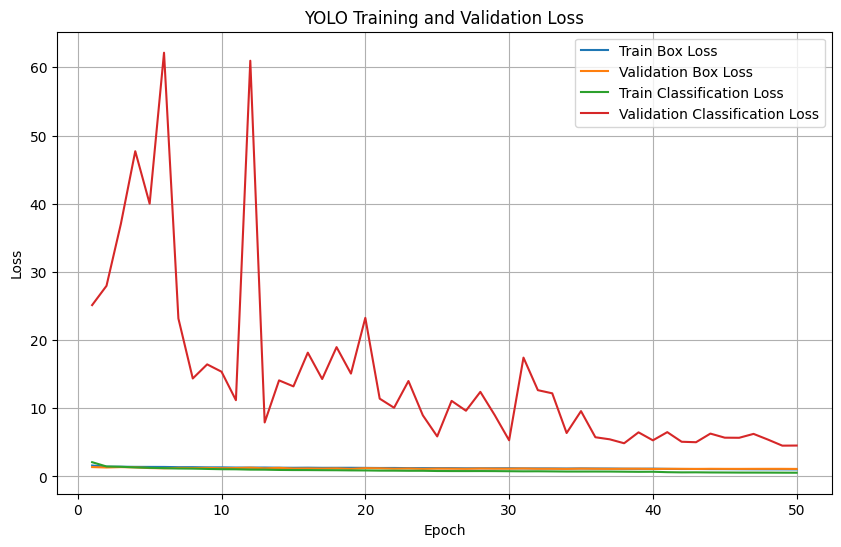

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

csv_path = "/content/runs/Pill_anomaly_Detection/results.csv"

df = pd.read_csv(csv_path)

# Remove whitespace from column names
df.columns = df.columns.str.strip()

plt.figure(figsize=(10, 6))

plt.plot(
    df["epoch"],
    df["train/box_loss"],
    label="Train Box Loss"
)

plt.plot(
    df["epoch"],
    df["val/box_loss"],
    label="Validation Box Loss"
)

plt.plot(
    df["epoch"],
    df["train/cls_loss"],
    label="Train Classification Loss"
)

plt.plot(
    df["epoch"],
    df["val/cls_loss"],
    label="Validation Classification Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLO Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()